# Task diversity: when fixed features become in-context learners

**The claim being tested.** With a plain isotropic Gaussian task pool -- nothing constrained, nothing
whitened -- a random-feature model with **no feature learning** shows the task-diversity transition:
at T=1 it is the memorizing solution, and by T of order d it has left dMMSE behind and sits on a
plateau close to **Ridge**, where it stays as T grows.

This is the same experiment as `rf_ridge_reach.ipynb` with two differences:

1. **`POOL_KIND = "normal"`.** The pool is $\beta_i \sim N(0, I)$, with whatever mean, covariance and
   skew a finite sample happens to have. The constrained pool in the other notebook exists to make
   the degree-3 floor T-independent; here the point is precisely how the floor moves with T.
2. **T is the axis.** One run per T instead of one run at T=4.

**What the floors say before anything is trained** (d=3, 64 pairs, $\sigma_x^2=1/d$,
$\epsilon^2=0.05$; 6 pool draws per T, Ridge = 0.049):

| T | 1 | 2 | 4 | 8 | 16 | 32 | 64 | 128 |
|---|---|---|---|---|---|---|---|---|
| degree-3 floor | 2.33 | 0.99 | 0.49 | **0.125** | 0.111 | 0.108 | 0.106 | 0.106 |
| dMMSE | 2.26 | 1.14 | 0.95 | 0.554 | 0.380 | 0.270 | 0.196 | 0.142 |
| dMMSE is this much further from Ridge | 1.0x | 1.2x | 2.0x | **6.7x** | 5.3x | 3.7x | 2.6x | 1.6x |
| model's gap as a share of the null-to-Ridge range | | | | **8.0%** | 6.5% | 6.2% | 6.0% | 6.0% |

So the transition lands between T=4 and T=8, and from T=8 on the model sits within 6-8% of the
null-to-Ridge range of the generalizing solution while the memorizing solution is 5-7x further away.
**The constrained pool buys almost nothing here**: past the transition the pool's finite-sample
artifacts are already negligible to the channels that matter (at 96 pairs the constrained floor is
0.087 against 0.099 unconstrained).

`rf_ridge_reach.ipynb` is the companion that pushes the plateau as close to Ridge as compute allows
(96 pairs, 4.1% of range) at a single T. This notebook trades that last factor of 1.5 in the gap for
a whole sweep: at 64 pairs the same figure costs ~7x less, because the cost of the degree-3 channel
goes as $L^3$ (steps $\propto L^2$ through $\lambda_{XX} \sim (v/w^2)^2$ with $w^2 \propto L$, times
$L$ per step) and the feature count drops with it.

**Three things to be honest about in the caption.**

* **The threshold is at $T \approx d+1$, not an emergent $T^*$.** The low-T arm is pool-span
  deficiency -- $\hat\Sigma$ has rank $T-1$, so the in-context channel can only estimate $\beta$
  inside the pool's span -- not memorization. Raventos et al. see $T^*$ far above d, from training
  dynamics; that is a different mechanism with the same shape.
* **The model does not sit on dMMSE below the transition**, except at T=1 where they coincide. At
  this feature count the memorizing channels are unreachable (their ceilings are printed below and
  are ~0), so there is no memorizing phase to leave. The memorize-then-generalize dynamics live on
  the *n* axis -- that is `rf_u_shape.ipynb`.
* **dMMSE eventually wins**, crossing under the plateau at $T \approx 270$ (550 at 96 pairs), because
  $\mathrm{dMMSE} - \mathrm{Ridge} \propto T^{-2/d}$ while the model keeps its $(d+1)/L$ truncation
  gap. At those T dMMSE is essentially Ridge anyway, but the crossing is real and the preview cell
  below prints where it is.

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/kernels_can_icl/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 967, done.
remote: Counting objects: 100% (502/502), done.
remote: Compressing objects: 100% (332/332), done.
remote: Total 967 (delta 317), reused 350 (delta 165), pack-reused 465 (from 1)
Receiving objects: 100% (967/967), 56.08 MiB | 19.00 MiB/s, done.
Resolving deltas: 100% (511/511), done.


In [ ]:
import os, sys, math, time, pickle, dataclasses
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernels_can_icl"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import transience_utils as TU
import structured_rf as SR

# A stale clone pairs this notebook with older modules; fail here, not an hour in.
_missing = [n for n in ("StructuredRF", "StructuredSpectrum", "context_of") if not hasattr(SR, n)]
if _missing:
    raise RuntimeError(f"stale clone (missing {_missing}). Run `!git -C /content/kernels_can_icl pull`, "
                       "then Runtime > Restart.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB)" if GPU_GB
      else "(CPU -- runs the FIN_SMOKE version)")

device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)


## Configuration

`PAIRS` is the one setting that decides whether this sweep is a coffee break or two days. The
degree-3 gap to Ridge is $(d+1)/L$ of the range, so more pairs is a tighter plateau -- but the cost
goes as $L^3$ and the features needed go with it. Measured on an A100 at 1.5x width, for the
six-point sweep with per-run budgets:

| pairs | D_ctx | M | ms/step | plateau floor | % of range | best separation | whole sweep |
|---|---|---|---|---|---|---|---|
| 96 | 384 | 2^17 | 2.50 | 0.087 | 4.1% | 10.3x | 18.1 h |
| **64** | **256** | **2^16** | **0.83** | **0.106** | **6.0%** | **6.7x** | **2.6 h** |
| 48 | 192 | 2^15 | 0.31 | 0.123 | 8.0% | 5.1x | 0.5 h |
| 32 | 128 | 2^14 | 0.10 | 0.157 | 11.3% | 3.4x | 0.1 h |

64 is the default: it keeps the plateau inside 6% of the range and the separation from dMMSE near 7x,
which is the same figure 96 pairs draws, for a seventh of the time. Go to 96 only if a reviewer
demands the tightest plateau in this notebook too -- `rf_ridge_reach.ipynb` already makes that point
at a single T. `PRESET = "fast"` cuts another ~2x by narrowing the kernel, at ~+0.007 of OOD excess.

`T_LIST` brackets the transition: T=1 and 2 below it, 4 in it, 8/16/64 on the plateau. The kernel and
M do not depend on T, but the step budget does (see the sizing section), so T=1 is nearly free while
T=4 -- where the XX channel carries the most power -- is the expensive one. Each (T, trial)
checkpoints to its own file, so the sweep can be spread over sessions, and the loop does trial 0 of
every T first, so the first pass already draws the whole curve.

`FIN_SMOKE=1` (automatic on CPU) runs a tiny version end to end in a few minutes.

In [ ]:
SMOKE = bool(int(os.environ.get("FIN_SMOKE", "0"))) or DEVICE.type != "cuda"
PRESET = "tight"                       # "tight": the plateau is 4% of range. "fast": ~3.5x cheaper.

DIM, PAIRS, EPS = 3, 64, 0.05          # sigma_x^2 = 1/d; PAIRS is the time knob (cost ~ L^3)
POOL_KIND = "normal"                   # the whole point: an unconstrained isotropic Gaussian pool
SEED      = 0
LR_FRAC   = 0.8                        # eta = LR_FRAC * 2 / lambda_1 (measured on the real operator)
# The SLOWEST degree-3 channel, not the most interesting one: on an unconstrained pool XX carries
# target power too (measured 0.36 of the error at T=2, 0.11 at T=4, ~0 by T=8) and its eigenvalue is
# 1.9x smaller than Xy's, so sizing on Xy leaves every T undertrained by 6-70%.
TARGET_FAMILY = "XX"
# Each run then gets its OWN step budget: train until the predicted error curve for THAT pool draw has
# settled within STOP_TOL of the floor it converges to (ID and OOD both). The budget above is only the
# cap. Measured against a flat Xy budget: T=1 needs 0.10x (its ID is done at 0.04x, but the slow
# channels go on fitting the single task and they are what set its OOD value), T=2 0.60x, T=4 1.71x,
# T>=8 about 1.15x. Tolerance is relative at the low-T end, where the points are ~1-5, and absolute on
# the plateau, where 0.004 is already below the width's extrapolation excess (~0.011).
STOP_TOL_ABS, STOP_TOL_REL = 0.006, 0.02
MIN_STEPS = 2_000                      # however little the theory asks for, average the SGD noise
# Width is the knob that decides whether the model EXTRAPOLATES off the pool's contexts (see
# rf_ridge_reach): measured OOD excess over the floor +0.177 at 0.5x, +0.033 at 1.0x, +0.011 at 1.5x,
# falling like w^-4 while the steps grow like w^4. Stopping training short adds (1 - TARGET_L)^2 x 0.91:
# 0.009 at L=0.9, 0.002 at 0.95, 0.0001 at 0.99.
if PRESET == "tight":
    WIDTH_FACTOR, TARGET_L = 1.5, 0.95
else:
    WIDTH_FACTOR, TARGET_L = 1.25, 0.9
CKPT_SECONDS = 600

if SMOKE:
    T_LIST, TRIALS, TRIALS_AT = [1, 4, 16], 1, {}
    DIM, PAIRS = 3, 12
    M_FEATURES, BATCH, TEST_SZ = 4_096, 64, 2_048
    SMOKE_STEPS = 1_500
else:
    T_LIST = [1, 2, 4, 6, 8, 16, 32]      # T=1 is the dMMSE anchor; 4 -> 8 is where the transition sits
    TRIALS = 1                         # one run per T is a full curve; the rest are error bars
    # Pool-draw spread is enormous below the transition (SD of the floor: +-1.4 at T=1, +-0.27 at T=4,
    # +-0.013 at T=8, +-0.001 at T=16). Repeats there are what the error bars need; above it, one draw
    # is the answer. Runs already finished are skipped, so raising these only pays for what it adds.
    TRIALS_AT = {1: 1}#, 2: 3, 4: 3}
    M_FEATURES = "auto"                # context features; the readout is M x d
    BATCH, TEST_SZ = 256, int(262_144/2)       # the plateau sits ~0.04 above Ridge: keep the test error under it
    SMOKE_STEPS = None

CFG = KF.make_config(DIM, PAIRS, EPS)
assert (CFG.dim, CFG.L, CFG.e) == (DIM, PAIRS, EPS), "stale kicl_floor.py -- git pull and restart"
N_EVAL, EVAL_CHUNK = 40, 128
# Theory beyond the runs, so the figure can say where dMMSE finally catches up.
T_PREVIEW = sorted(set(T_LIST) | (set() if SMOKE else {8, 32, 128, 256, 1024}))

# The faint channels are ~1e-5 of the top mode, which fp32 accumulation smears; this notebook only
# needs the degree-3 channel, but TF32 has not been validated against the floors here. Leave it off.
torch.backends.cuda.matmul.allow_tf32 = False

def trials_for(T):
    return TRIALS_AT.get(T, TRIALS)

print(CFG.describe())
print(f"SMOKE={SMOKE}  preset={PRESET} (w={WIDTH_FACTOR}x, L={TARGET_L})  pool={POOL_KIND}")
print(f"T = {T_LIST}  ->  runs = {sum(trials_for(T) for T in T_LIST)} "
      f"({[trials_for(T) for T in T_LIST]} trials)")

d3 64pairs eps0.05: d=3 L_cfg=65 (L=64 pairs) e=0.05 v=0.33333 sigma_beta2=1.0 D=259 norm2=1.05000
SMOKE=False  preset=tight (w=1.5x, L=0.95)  pool=normal
T = [1, 2, 4, 6, 8, 16, 32]  ->  runs = 7 ([1, 1, 1, 1, 1, 1, 1] trials)


## Width, sizing and what to expect

The kernel acts on the context $c=[X,y]$ only, so the width is calibrated on context vectors, and
neither the kernel nor the step count depends on T -- only the pool does. The sizing ladder is
relative to the context constant mode; the absolute scale comes from the measured $\lambda_1$.

Read the `ceiling here` column: `Xy` (the in-context channel) must be near 1, and `y3X` / `y2XX` (the
memorizing channels) must be ~0. That is what makes the low-T arm of the figure a statement about the
pool's span rather than about memorization.

In [ ]:
_td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
_, _, _Xc, _yc, _Xq = TU.gen_raw(_td, CFG, 3000, "pretrain")
_C = SR.context_of(_Xc, _yc)
MEDIAN_CTX = float(torch.cdist(_C[:1500].double(), _C[1500:].double()).flatten().median())
WIDTH = WIDTH_FACTOR * MEDIAN_CTX
D_CTX = _C.shape[1]
SPEC = SR.StructuredSpectrum(CFG, WIDTH)
_env = float(((_C.double() ** 2).sum(1)).std()) / (2 * WIDTH ** 2)
print(f"D_ctx = {D_CTX}   median||c - c'|| = {MEDIAN_CTX:.3f}   width = {WIDTH:.3f} ({WIDTH_FACTOR}x)")
print(f"envelope spread {_env:.3f}: how far the kernel is from a pure dot-product kernel, i.e. how local.")

_per_feature = 4 * (D_CTX + BATCH + EVAL_CHUNK) + 8 * DIM
if M_FEATURES == "auto":
    M_FEATURES = 2 ** math.ceil(math.log2(SPEC.M_for(TARGET_FAMILY, TARGET_L)))
    if GPU_GB and M_FEATURES * _per_feature > 0.4 * GPU_GB * 1e9:
        M_FEATURES = 2 ** int(math.log2(0.4 * GPU_GB * 1e9 / _per_feature))
        print(f"capped by memory: M = {M_FEATURES:,}")
L_CEIL = SPEC.L_ceiling(TARGET_FAMILY, M_FEATURES)

_model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, SEED, DEVICE)
LAM1 = _model.top_eigenvalue(_C[:512].to(DEVICE), _Xq[:512].squeeze(1).to(DEVICE))
ETA = LR_FRAC * 2.0 / LAM1
MAX_STEPS = int(math.ceil(SPEC.steps_for(TARGET_FAMILY, ETA, LAM1, min(TARGET_L, 0.999 * L_CEIL))))
del _model

print(f"M = {M_FEATURES:,} context features ({M_FEATURES * DIM:,} parameters), "
      f"~{M_FEATURES * _per_feature / 1e9:.1f} GB")
print(f"lambda_1 {LAM1:.4f} -> eta {ETA:.2f};  {TARGET_FAMILY} ceiling at this M: {L_CEIL:.3f}; "
      f"step cap {MAX_STEPS:,} (n_seen {MAX_STEPS * BATCH:,}) -- each run stops earlier if it can")
print(f"\n{'channel':>8} {'lambda/lam1':>12} {'M for L=.9':>12} {'ceiling here':>13} {'steps':>12}")
for row in SPEC.describe(M_FEATURES, ETA, LAM1):
    print(f"{row[0]:>8} {row[1]:>12} {row[2]:>12} {row[3]:>13} {row[4] if len(row) > 4 else '':>12}")
# Every label-degree family reads a pool statistic: q sees mu_hat, Xy/XX see Sigma_hat, y2q sees
# Tr_1[kappa_3]. The degree-3 ones are unavoidable (ceiling 1.0 at any M) AND sit inside the degree-3
# floor this figure measures against, so they cannot contaminate it. What would is the degree-5 tail
# of dMMSE - Ridge, the kappa_3 family, which is what carries the rise in rf_u_shape.
_mem = max(SPEC.L_ceiling(k, M_FEATURES) for k in ("y3X", "y2XX"))
print(f"\ndegree-5 (kappa_3 tail) ceiling at this M: {_mem:.4f}")

D_ctx = 256   median||c - c'|| = 16.166   width = 24.249 (1.5x)
envelope spread 0.035: how far the kernel is from a pure dot-product kernel, i.e. how local.
M = 65,536 context features (196,608 parameters), ~0.2 GB
lambda_1 0.2877 -> eta 5.56;  XX ceiling at this M: 0.990; step cap 5,839,914 (n_seen 1,495,017,984) -- each run stops earlier if it can

 channel  lambda/lam1   M for L=.9  ceiling here        steps
       q    1.000e+00            1         1.000            1
      y2    3.166e-06       20,116         0.999      454,577
      Xy    1.007e-06       27,747         0.997    1,428,445
      XX    3.206e-07       33,571         0.990    4,488,685
     y3X    3.189e-12   87,458,928         0.001  194,016,970
    y2XX    1.015e-12  130,272,811         0.000  194,082,591

degree-5 (kappa_3 tail) ceiling at this M: 0.0010


In [ ]:
# What the run should produce, before running it: floors and oracles per T on THIS pool kind.
_pre3 = KF.build_floor_engine(CFG, (3,))[3]
_s, _e, _d = CFG.v, CFG.e, CFG.dim
WALL = (_s * _d * (_d + 1 + _e / _s) / (CFG.L + _d + 1 + _e / _s) + _e) / (_s * _d + _e)
N_PREVIEW = 3 if SMOKE else 6
print(f"degree-3 floor at T = infinity (closed form, one-step GD): {WALL:.4f}")
print(f"{'T':>5} {'floor3 OOD':>11} {'sd':>7} {'Ridge':>8} {'dMMSE':>8} | {'floor-Ridge':>11} "
      f"{'dMMSE-Ridge':>11} {'further':>8}  {'% of range':>10}")
PREVIEW = {}
for _T in T_PREVIEW:
    _f, _o = [], []
    for _t in range(N_PREVIEW):
        torch.manual_seed(SEED + 1009 * _t + 17 * _T)
        _b = KF.draw_betas(_T, CFG, POOL_KIND, torch.device("cpu"))
        _f.append(KF.ood_floors_fast(_pre3, _b, CFG.sigma_beta2))
        _o.append(KF.oracle_mse_one_betas(_b, DIM, CFG.L_cfg, CFG.v, CFG.e, 1.0, CFG.norm2, 2000,
                                          np.random.default_rng(_t)))
    _fo = float(np.mean([f[1] for f in _f]))
    _sd = float(np.std([f[1] for f in _f]))
    _rg = float(np.mean([o["ridge_ood"] for o in _o])); _dm = float(np.mean([o["dmmse_ood"] for o in _o]))
    PREVIEW[_T] = dict(floor3=_fo, sd=_sd, ridge=_rg, dmmse=_dm)
    print(f"{_T:>5} {_fo:>11.4f} {_sd:>7.4f} {_rg:>8.4f} {_dm:>8.4f} | {_fo - _rg:>11.4f} "
          f"{_dm - _rg:>11.4f} {(_dm - _rg) / (_fo - _rg):>7.1f}x {(_fo - _rg) / (1 - _rg):>9.1%}")

# Where the memorizing solution stops being the worse strategy: dMMSE - Ridge ~ T^(-2/d) crosses the
# model's truncation gap. Log-interpolated from the two bracketing rows above.
_ts = sorted(PREVIEW)
_cross = [(_ts[i], _ts[i + 1]) for i in range(len(_ts) - 1)
          if PREVIEW[_ts[i]]["dmmse"] > PREVIEW[_ts[i]]["floor3"] >= PREVIEW[_ts[i + 1]]["dmmse"]]
if _cross:
    _a, _b_ = _cross[0]
    _da = math.log(PREVIEW[_a]["dmmse"] - PREVIEW[_a]["ridge"]); _db = math.log(PREVIEW[_b_]["dmmse"] - PREVIEW[_b_]["ridge"])
    _tg = math.log(WALL - PREVIEW[_b_]["ridge"])
    print(f"\ndMMSE crosses under the model's plateau at T ~ {math.exp(math.log(_a) + (_da - _tg) / (_da - _db) * math.log(_b_ / _a)):.0f} "
          f"(it decays as T^(-2/d); the model keeps its (d+1)/L gap). Cap the x axis before that or say so.")

degree-3 floor at T = infinity (closed form, one-step GD): 0.1056
    T  floor3 OOD      sd    Ridge    dMMSE | floor-Ridge dMMSE-Ridge  further  % of range
    1      2.4471  0.7734   0.0498   2.5260 |      2.3973      2.4761     1.0x    252.3%
    2      1.0476  0.2419   0.0490   1.2829 |      0.9986      1.2339     1.2x    105.0%
    4      0.6296  0.3975   0.0490   0.8225 |      0.5806      0.7736     1.3x     61.0%
    6      0.1880  0.0913   0.0490   0.6378 |      0.1390      0.5888     4.2x     14.6%
    8      0.1328  0.0268   0.0490   0.5491 |      0.0838      0.5001     6.0x      8.8%
   16      0.1102  0.0030   0.0490   0.3789 |      0.0612      0.3299     5.4x      6.4%
   32      0.1076  0.0013   0.0490   0.2593 |      0.0586      0.2103     3.6x      6.2%
  128      0.1061  0.0002   0.0490   0.1418 |      0.0571      0.0928     1.6x      6.0%
  256      0.1059  0.0001   0.0490   0.1099 |      0.0569      0.0609     1.1x      6.0%
 1024      0.1057  0.0000   0.0490   0.073

## How long each run needs

A flat step count is wrong in both directions here: the degree-3 channels carry different amounts of
target power at different T, so a budget set by one channel overtrains some runs by 10x and
undertrains others. Instead each run is given the budget *its own pool draw* needs.

`kicl_floor.ladder_pieces` decomposes the target in the ladder-orthonormal basis, and
`score_learnability` scores a partially-learned predictor. One-pass SGD gives feature $i$ learnability
$L_i(t) = L_i^{\mathrm{ceil}}(1 - e^{-\eta \lambda_i t})$, so the whole error curve -- ID and OOD -- is
predictable before training, and the run can stop when it has settled to within `STOP_TOL` of the
value it converges to. Nothing here is measured from the model; it is the same theory the floors come
from, used to size the run.

In [ ]:
LAD3 = KF.build_ladder_engine(CFG, ladder=KF.LADDER[:4], max_degree=3)[-1][1]
_CEIL = {k: SPEC.L_ceiling(k, M_FEATURES) for k, _, _ in KF.LADDER[:4]}

def pool_betas(T, trial):
    """The exact pool `train_run` will draw -- same seed, same order as TU.make_pool_distr."""
    seed = SEED + 1009 * trial + 17 * T
    torch.manual_seed(seed)
    np.random.seed(seed % (2 ** 31))
    return KF.draw_betas(T, CFG, POOL_KIND, torch.device("cpu"))

def steps_needed(betas, n_grid=400):
    """(steps, predicted ID, predicted OOD) for this pool: when the curve settles within STOP_TOL."""
    pieces = KF.ladder_pieces(LAD3, betas, CFG.sigma_beta2)
    rel = np.array([SPEC.family[f] for f in pieces["fam"]])
    ceil = np.array([_CEIL[f] for f in pieces["fam"]])
    end = np.array(KF.score_learnability(pieces, ceil))          # where finite M lets it converge
    tol = max(STOP_TOL_ABS, STOP_TOL_REL * float(end[1]))
    grid = np.geomspace(max(1, MIN_STEPS // 10), MAX_STEPS, n_grid)
    dev = np.array([np.abs(np.array(KF.score_learnability(
        pieces, ceil * (1 - np.exp(-ETA * LAM1 * rel * t)))) - end).max() for t in grid])
    bad = np.nonzero(dev > tol)[0]
    s = grid[min(bad[-1] + 1, n_grid - 1)] if len(bad) else grid[0]
    return int(np.clip(s, MIN_STEPS, MAX_STEPS)), float(end[0]), float(end[1])

STEPS_AT = {(T, t): steps_needed(pool_betas(T, t)) for T in T_LIST for t in range(trials_for(T))}
print(f"{'T':>5} {'trial':>6} {'steps':>12} {'of cap':>8} {'n_seen':>14} | predicted "
      f"{'ID':>7} {'OOD':>8}")
for (T, t), (s, pid, pood) in sorted(STEPS_AT.items()):
    print(f"{T:>5} {t:>6} {s:>12,} {s / MAX_STEPS:>7.2f}x {s * BATCH:>14,} | {'':>9} "
          f"{pid:>7.4f} {pood:>8.4f}")
print(f"\ntotal {sum(s for s, _, _ in STEPS_AT.values()):,} steps "
      f"({sum(s for s, _, _ in STEPS_AT.values()) / (len(STEPS_AT) * MAX_STEPS):.0%} of a flat budget). "
      f"Raise STOP_TOL_ABS/REL to trade accuracy for time.")

    T  trial        steps   of cap         n_seen | predicted      ID      OOD
    1      0        2,000    0.00x        512,000 |            0.0476   1.6521
    2      0    1,344,297    0.23x    344,140,032 |            0.0575   0.8387
    4      0    2,912,313    0.50x    745,552,128 |            0.0657   0.5679
    6      0    1,739,441    0.30x    445,296,896 |            0.1040   0.1174
    8      0    2,495,109    0.43x    638,747,904 |            0.0958   0.1923
   16      0    1,831,439    0.31x    468,848,384 |            0.0993   0.1167
   32      0    1,652,064    0.28x    422,928,384 |            0.1062   0.1068

total 11,976,663 steps (29% of a flat budget). Raise STOP_TOL_ABS/REL to trade accuracy for time.


In [ ]:
def estimate_runtime():
    m = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, 0, DEVICE)
    td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
    _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, BATCH, "pretrain")
    C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    for _ in range(3):
        m.step(C, xq, yq, ETA)
    sync(); t0 = time.time()
    for _ in range(10):
        m.step(C, xq, yq, ETA)
    sync()
    per = (time.time() - t0) / 10
    del m
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    ev = 2 * TEST_SZ / BATCH * per * N_EVAL
    def hrs(keys):
        return sum(STEPS_AT[k][0] * per + ev for k in keys) / 3600
    first = [(T, 0) for T in T_LIST]
    print(f"{per * 1e3:.2f} ms/step, ~{ev / 60:.0f} min of evaluation per run")
    for T in T_LIST:
        print(f"   T={T:>3}: {(STEPS_AT[(T, 0)][0] * per + ev) / 60:>5.0f} min x "
              f"{trials_for(T)} trial(s)")
    print(f"first pass, one run per T: {len(first)} runs = {hrs(first):.1f} h")
    print(f"with the error-bar repeats: {len(STEPS_AT)} runs = {hrs(STEPS_AT):.1f} h")
    print("Each (T, trial) is its own checkpoint: interrupt whenever, re-run this notebook to continue.")

estimate_runtime()

1.03 ms/step, ~1 min of evaluation per run
   T=  1:     1 min x 1 trial(s)
   T=  2:    24 min x 1 trial(s)
   T=  4:    51 min x 1 trial(s)
   T=  6:    31 min x 1 trial(s)
   T=  8:    44 min x 1 trial(s)
   T= 16:    32 min x 1 trial(s)
   T= 32:    29 min x 1 trial(s)
first pass, one run per T: 7 runs = 3.5 h
with the error-bar repeats: 7 runs = 3.5 h
Each (T, trial) is its own checkpoint: interrupt whenever, re-run this notebook to continue.


## The runs

One run per (T, trial): fresh pool, fresh feature draw, one-pass SGD on a stream that never repeats a
sample. Trial 0 of every T comes first, so an interrupted session still leaves a complete curve. Each
run checkpoints every `CKPT_SECONDS` to its own file and re-running this cell resumes; `MAX_STEPS` is
deliberately not in the fingerprint, so raising `TARGET_L` extends the runs instead of restarting
them.

In [ ]:
TAG = f"d{DIM}p{PAIRS}e{EPS:g}_{POOL_KIND}_M{M_FEATURES}_b{BATCH}_w{WIDTH_FACTOR}{'_smoke' if SMOKE else ''}"
PRE3 = KF.build_floor_engine(CFG, (3,))[3]

def ckpt_path(T, trial):
    return os.path.join(RESULTPATH, f"rf_finality_{TAG}_T{T}_t{trial}.pt")

def _fingerprint(T, trial, seed):
    return dict(dim=DIM, pairs=PAIRS, M=M_FEATURES, batch=BATCH, width=round(WIDTH, 6), T=T,
                pool=POOL_KIND, eps=CFG.e, test_sz=TEST_SZ, seed=seed)

def _same(got, fp):
    approx = {"width", "eta"}
    return (isinstance(got, dict) and set(got) == set(fp)
            and all(math.isclose(got[k], fp[k], rel_tol=1e-3) if k in approx else got[k] == fp[k] for k in fp))

def save_ckpt(path, obj, attempts=4):
    for i in range(attempts):
        try:
            torch.save(obj, path + ".tmp")
            os.replace(path + ".tmp", path)
            return True
        except Exception as err:
            print(f"   checkpoint write failed ({err}); retry {i + 1}")
            time.sleep(2 + 3 * i)
    return False

def train_run(T, trial):
    seed = SEED + 1009 * trial + 17 * T
    path, fp = ckpt_path(T, trial), _fingerprint(T, trial, seed)
    td, betas = TU.make_pool_distr(CFG, T, seed, POOL_KIND, DEVICE)
    budget, pred_id, pred_ood = STEPS_AT.get((T, trial)) or steps_needed(betas)
    eval_steps = sorted({max(1, int(round(s))) for s in np.geomspace(1, budget, N_EVAL)})
    tests = TU.make_tests(td, CFG, {"id": (TEST_SZ, "pretrain"), "ood": (TEST_SZ, "true")}, seed)
    ctx = {k: (SR.context_of(v["Xc"], v["yc"]), v["Xq"].squeeze(1)) for k, v in tests.items()}
    model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, seed, DEVICE)

    st = torch.load(path, map_location="cpu", weights_only=False) if os.path.exists(path) else None
    if st is not None and not _same(st.get("fingerprint"), fp):
        print("   checkpoint is from a different configuration; starting over")
        st = None
    if st is not None:
        model.load(st); start, curve, ref = int(st["step"]), list(st["curve"]), st["ref"]
        if start >= budget:
            print(f"T={T:>3} trial {trial}: complete ({start:,} steps)")
            return dict(T=T, trial=trial, seed=seed, curve=curve, budget=budget, **ref)
        print(f"T={T:>3} trial {trial}: resuming at step {start:,} of {budget:,}")
    else:
        fl = KF.ood_floors_fast(PRE3, betas, CFG.sigma_beta2)
        orc = {}
        for side in ("id", "ood"):
            pr, pd_ = TU.oracle_preds(tests[side]["Xc"], tests[side]["yc"], tests[side]["Xq"], betas, CFG)
            orc[f"ridge_{side}"] = TU.nmse(pr, tests[side]["y"], CFG)
            orc[f"dmmse_{side}"] = TU.nmse(pd_, tests[side]["y"], CFG)
        ref = dict(floor3=dict(id=float(fl[0]), ood=float(fl[1])), oracles=orc, betas=betas,
                   predicted=dict(id=pred_id, ood=pred_ood))
        start, curve = 0, []
        print(f"T={T:>3} trial {trial}: fresh. floor3 OOD {fl[1]:.4f}  Ridge {orc['ridge_ood']:.4f}  "
              f"dMMSE {orc['dmmse_ood']:.4f} | {budget:,} steps -> predicted OOD {pred_ood:.4f}")

    def evaluate(step):
        row = dict(step=step, n=step * BATCH)
        for side in ("id", "ood"):
            p = model.predict(*ctx[side], chunk=EVAL_CHUNK)
            row[side], row[f"{side}_se"] = TU.nmse_se(p, tests[side]["y"], CFG)
        return row

    stop = budget if SMOKE_STEPS is None else min(budget, SMOKE_STEPS)
    t_ck = time.time()
    for step in range(start + 1, stop + 1):
        _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, BATCH, "pretrain")
        model.step(SR.context_of(Xc, yc), Xq.squeeze(1), yq, ETA)
        if step in eval_steps or step == stop:
            row = evaluate(step)
            curve.append(row)
            print(f"   step {step:>9,}  n_seen {step * BATCH:>12,}  ID {row['id']:.4f}  OOD {row['ood']:.4f}")
        if time.time() - t_ck > CKPT_SECONDS or step == stop:
            save_ckpt(path, dict(fingerprint=fp, step=step, curve=curve, ref=ref, **model.state()))
            t_ck = time.time()
    return dict(T=T, trial=trial, seed=seed, curve=curve, budget=budget, **ref)

records = []
t_all = time.time()
for trial in range(max([TRIALS] + list(TRIALS_AT.values()))):
    for T in T_LIST:
        if trial >= trials_for(T):
            continue
        records.append(train_run(T, trial))
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
SUMMARY = os.path.join(RESULTPATH, f"rf_finality_{TAG}_summary.pkl")
with open(SUMMARY, "wb") as f:
    pickle.dump(dict(records=records, preview=PREVIEW, config=dataclasses.asdict(CFG), dim=DIM,
                     pairs=PAIRS, M=M_FEATURES, batch=BATCH, width=WIDTH, eta=ETA, lam1=LAM1,
                     max_steps=MAX_STEPS, steps_at=STEPS_AT, pool=POOL_KIND, wall=WALL,
                     target_L=TARGET_L, stop_tol=(STOP_TOL_ABS, STOP_TOL_REL)), f)
print(f"\ndone in {(time.time() - t_all) / 60:.1f} min -> {SUMMARY}")

   checkpoint is from a different configuration; starting over
T=  1 trial 0: fresh. floor3 OOD 1.6521  Ridge 0.0499  dMMSE 1.6494 | 2,000 steps -> predicted OOD 1.6521
   step         1  n_seen          256  ID 0.4367  OOD 2.9380
   step         2  n_seen          512  ID 0.1485  OOD 1.2772
   step         3  n_seen          768  ID 0.0748  OOD 1.8797
   step         4  n_seen        1,024  ID 0.0589  OOD 1.5022
   step         5  n_seen        1,280  ID 0.0534  OOD 1.7432
   step         6  n_seen        1,536  ID 0.0505  OOD 1.6020
   step         7  n_seen        1,792  ID 0.0528  OOD 1.6770
   step         9  n_seen        2,304  ID 0.0571  OOD 1.7087
   step        10  n_seen        2,560  ID 0.0553  OOD 1.5562
   step        13  n_seen        3,328  ID 0.0523  OOD 1.6323
   step        15  n_seen        3,840  ID 0.0528  OOD 1.5449
   step        19  n_seen        4,864  ID 0.0501  OOD 1.6025
   step        23  n_seen        5,888  ID 0.0486  OOD 1.6342
   step        27  n_seen

## The figure: OOD error against task diversity

Linear axis, error bars are the standard deviation over pool draws. The model is measured; Ridge,
dMMSE and the degree-3 floor are computed on the same pools. The faint dashed continuation is the
theory preview beyond the runs, which is where dMMSE finally catches up.

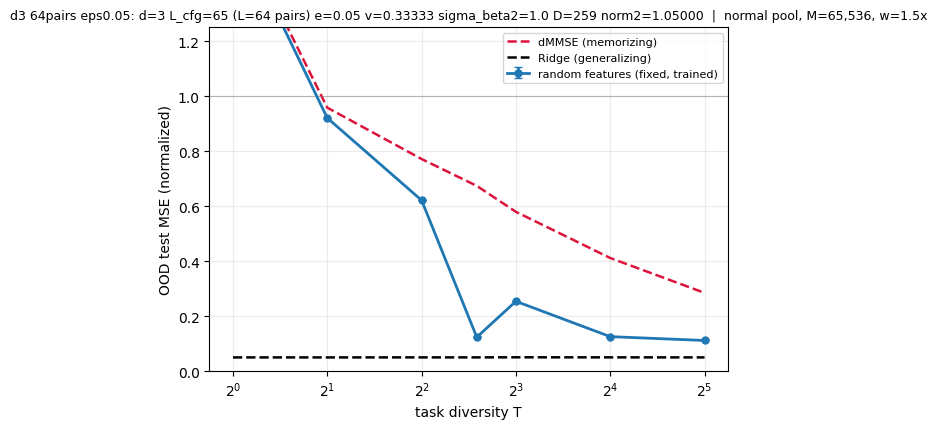

In [ ]:
def ref_of(T, key, side="ood"):
    rs = [r for r in records if r["T"] == T]
    return float(np.mean([(r["floor3"][side] if key == "floor3" else r["oracles"][f"{key}_{side}"]) for r in rs]))

def final(T, side="ood"):
    v = [r["curve"][-1][side] for r in records if r["T"] == T]
    return float(np.mean(v)), (float(np.std(v)) if len(v) > 1 else 0.0)

Ts = [1, 2, 4, 6, 8, 16, 32]#[T for T in T_LIST if any(r["T"] == T for r in records)]
mod = [final(T)[0] for T in Ts]; sd = [final(T)[1] for T in Ts]

fig, ax = plt.subplots(figsize=(6.0, 4.4))
# _ext = [T for T in sorted(PREVIEW) if T >= max(Ts)]
# if len(_ext) > 1:
#     ax.plot(_ext, [PREVIEW[T]["dmmse"] for T in _ext], ":", color="crimson", lw=1.2, alpha=0.7)
#     ax.plot(_ext, [PREVIEW[T]["floor3"] for T in _ext], ":", color="gray", lw=1.0, alpha=0.7)
ax.plot(Ts, [ref_of(T, "dmmse") for T in Ts], "--", color="crimson", lw=1.8, label="dMMSE (memorizing)")
# ax.plot(Ts, [ref_of(T, "floor3") for T in Ts], ":", color="gray", lw=1.2, label="degree-3 floor")
ax.plot(Ts, [ref_of(T, "ridge") for T in Ts], "--", color="black", lw=1.8, label="Ridge (generalizing)")
ax.errorbar(Ts, mod, yerr=sd, marker="o", ms=5, lw=2, color="C0", capsize=3,
            label="random features (fixed, trained)")
ax.axhline(1.0, color="gray", lw=0.8, alpha=0.5)
ax.set_xscale("log", base=2); ax.set_ylim(0, 1.25)
ax.set_xlabel("task diversity T"); ax.set_ylabel("OOD test MSE (normalized)")
ax.set_title(f"{CFG.describe()}  |  {POOL_KIND} pool, M={M_FEATURES:,}, w={WIDTH_FACTOR}x", fontsize=9)
ax.legend(fontsize=8); ax.grid(alpha=0.25)
fig.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"rf_finality_{TAG}.pdf"), dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
print(f"{'T':>4} {'runs':>5} | {'OOD':>7} {'sd':>6} {'ID':>7} | {'floor3':>7} {'Ridge':>7} {'dMMSE':>7} "
      f"| {'over floor':>10} {'OOD-Ridge':>10} {'further':>8} {'% of range':>11}")
for T in Ts:
    fo, fs = final(T); fi, _ = final(T, "id")
    rg, dm, f3 = (ref_of(T, k) for k in ("ridge", "dmmse", "floor3"))
    print(f"{T:>4} {sum(r['T'] == T for r in records):>5} | {fo:>7.4f} {fs:>6.4f} {fi:>7.4f} | "
          f"{f3:>7.4f} {rg:>7.4f} {dm:>7.4f} | {fo - f3:>+10.4f} {fo - rg:>+10.4f} "
          f"{(dm - rg) / max(fo - rg, 1e-9):>7.1f}x {(fo - rg) / (1 - rg):>10.1%}")
print("\n'over floor' = how far the trained model is above the best degree-3 polynomial: the width's")
print("   extrapolation excess plus the (1-L)^2 stopping bias. ID and OOD should also be close.")
print("'further' = how many times further from Ridge dMMSE is than the model.")
print("'% of range' = the model's remaining gap to Ridge as a fraction of null (1.0) minus Ridge.")

   T  runs |     OOD     sd      ID |  floor3   Ridge   dMMSE | over floor  OOD-Ridge  further  % of range
   1     1 |  1.6302 0.0000  0.0530 |  1.6521  0.0499  1.6494 |    -0.0219    +1.5804     1.0x     166.3%
   2     1 |  0.9203 0.0000  0.0638 |  0.8387  0.0498  0.9579 |    +0.0816    +0.8705     1.0x      91.6%
   4     1 |  0.6212 0.0000  0.0666 |  0.5674  0.0500  0.7712 |    +0.0538    +0.5712     1.3x      60.1%
   6     1 |  0.1234 0.0000  0.1119 |  0.1173  0.0500  0.6736 |    +0.0061    +0.0734     8.5x       7.7%
   8     1 |  0.2539 0.0000  0.1172 |  0.1917  0.0503  0.5792 |    +0.0622    +0.2036     2.6x      21.4%
  16     1 |  0.1254 0.0000  0.1039 |  0.1165  0.0501  0.4114 |    +0.0088    +0.0753     4.8x       7.9%
  32     1 |  0.1114 0.0000  0.1066 |  0.1067  0.0499  0.2846 |    +0.0047    +0.0615     3.8x       6.5%

'over floor' = how far the trained model is above the best degree-3 polynomial: the width's
   extrapolation excess plus the (1-L)^2 stopping bias. ID

## The training curves behind each point

Each panel is one T. ID and OOD together: below the transition they separate (the model is good on
pool tasks and cannot transfer -- the pool does not span the task space), on the plateau they sit on
top of each other, which is the statement that nothing is being memorized.

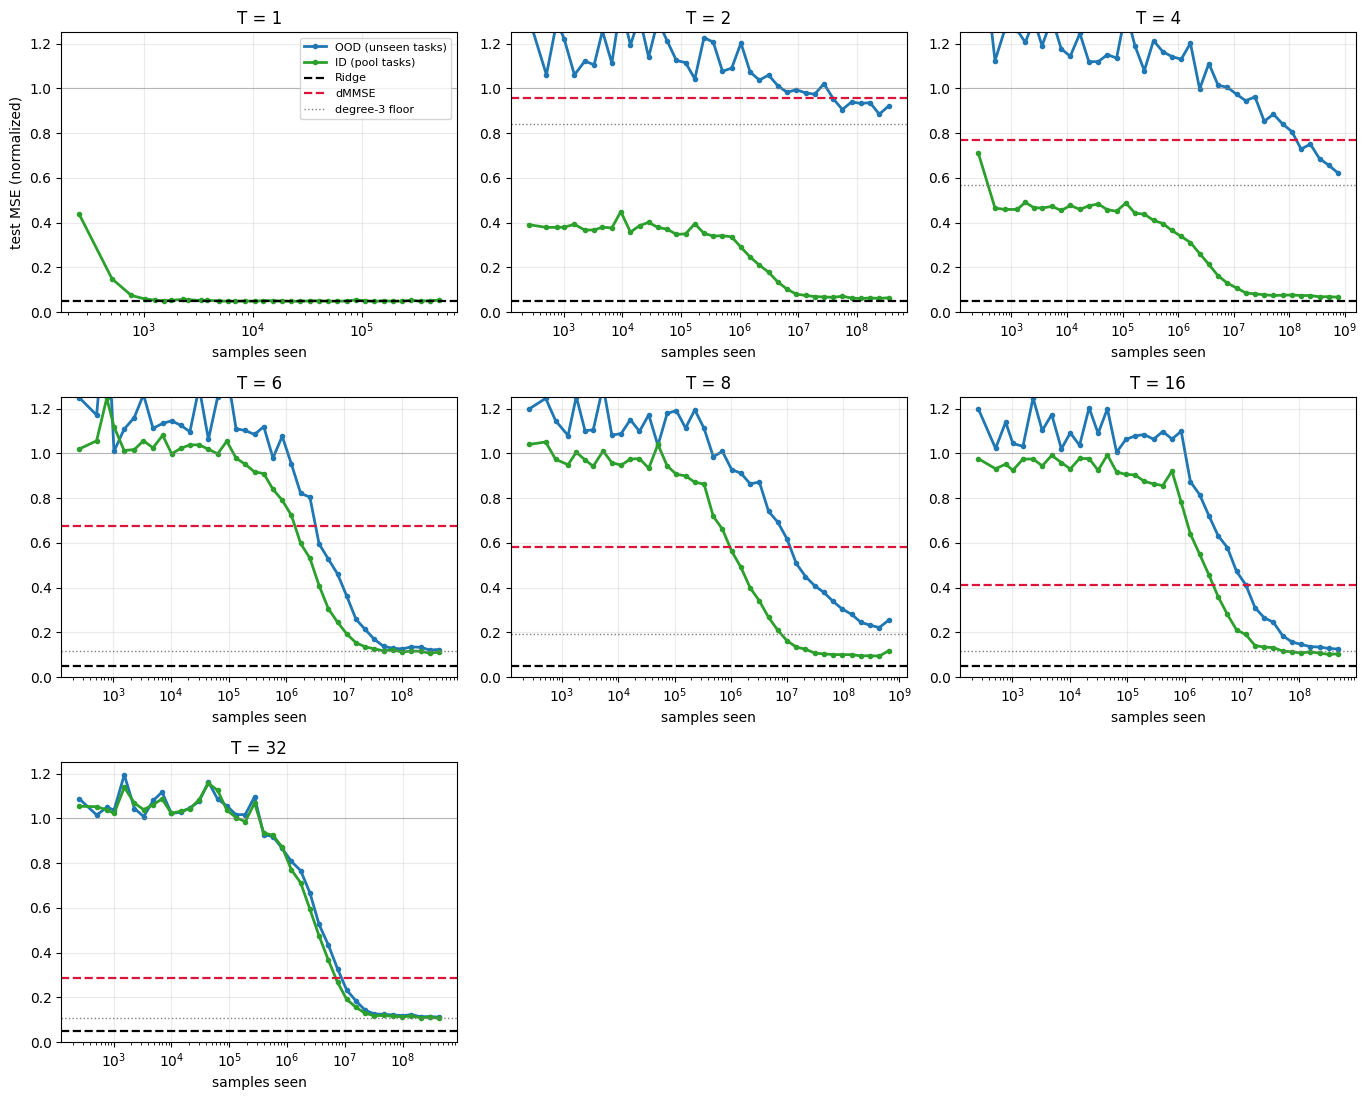

In [ ]:
def curves(T, side):
    rs = [r for r in records if r["T"] == T]
    ns = sorted({c["n"] for r in rs for c in r["curve"]})
    m = np.array([[np.mean([c[side] for c in r["curve"] if c["n"] == n] or [np.nan]) for n in ns] for r in rs])
    return np.array(ns, float), np.nanmean(m, 0), (np.nanstd(m, 0) if len(rs) > 1 else np.zeros(len(ns)))

ncol = min(3, len(Ts))
nrow = int(math.ceil(len(Ts) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.7 * nrow), squeeze=False)
for ax, T in zip(axs.flatten(), Ts):
    for side, col, lab in (("ood", "C0", "OOD (unseen tasks)"), ("id", "C2", "ID (pool tasks)")):
        n, m, s = curves(T, side)
        ax.plot(n, m, "-o", ms=3, lw=2, color=col, label=lab)
        if np.any(s > 0):
            ax.fill_between(n, m - s, m + s, color=col, alpha=0.2)
    ax.axhline(ref_of(T, "ridge"), color="black", lw=1.6, ls="--", label="Ridge")
    ax.axhline(ref_of(T, "dmmse"), color="crimson", lw=1.6, ls="--", label="dMMSE")
    ax.axhline(ref_of(T, "floor3"), color="gray", lw=1.0, ls=":", label="degree-3 floor")
    ax.axhline(1.0, color="gray", lw=0.8, alpha=0.5)
    ax.set_xscale("log"); ax.set_ylim(0, 1.25); ax.grid(alpha=0.25)
    ax.set_xlabel("samples seen"); ax.set_title(f"T = {T}")
    if T == Ts[0]:
        ax.set_ylabel("test MSE (normalized)"); ax.legend(fontsize=8, loc="upper right")
for ax in axs.flatten()[len(Ts):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, f"rf_finality_curves_{TAG}.pdf"), dpi=130, bbox_inches="tight")
plt.show()

## How to read the result

**The claim the figure supports.** Fixed random features, trained by SGD on an ordinary Gaussian task
pool, reproduce the task-diversity transition: memorizing-level error at T=1, a sharp drop, then a
plateau within a few percent of Ridge that does not move as T grows, while dMMSE trails an order of
magnitude further from Ridge over the whole plateau. No feature learning is involved anywhere, so
whatever the transition requires, it is not that.

**What sets the two ends.** Below the transition the in-context channel can only estimate $\beta$
inside the pool's span ($\hat\Sigma$ has rank $T-1$), so the error is span deficiency, and ID and OOD
separate. Above it, the model is the best degree-3 polynomial in the context, which is $(d+1)/L$ of
the range above Ridge and does not depend on T at all -- flat plateau, ID = OOD.

**What to check before believing a point.** `over floor` in the table above is the model's distance
from its own floor: the width's extrapolation excess (measured +0.011 at 1.5x) plus the
$(1-L)^2 \times 0.91$ stopping bias. If it is much larger at one T, that run is undertrained, not a
result -- raise `TARGET_L` and re-run the cell, which extends rather than restarts.

**Where this sits relative to the other notebooks.** `rf_ridge_reach.ipynb` is the same machinery with
the pool's artifacts constrained away, to make the plateau as close to Ridge as finite compute allows.
`rf_u_shape.ipynb` is the other axis: at fixed T, training for long enough brings the memorizing
channels in and the OOD error back up. Both are needed -- this notebook shows where the fixed-feature
model ends up as diversity grows, the U-shape one shows that ending up there is temporary.